In [2]:
import pandas as pd
from sklearn.linear_model import LogisticRegression

In [3]:
#dir(pd)

In [4]:
#Load the data set
claimants = pd.read_csv('claimants.csv')
claimants.head()

,CASENUM,ATTORNEY,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
0,5,0,0.0,1.0,0.0,50.0,34.940
1,3,1,1.0,0.0,0.0,18.0,0.891
2,66,1,0.0,1.0,0.0,5.0,0.330
3,70,0,0.0,1.0,1.0,31.0,0.037
4,96,1,0.0,1.0,0.0,30.0,0.038


In [5]:
#dropping the case nummber as it is not rquired 
claimants.drop(["CASENUM"],inplace=True,axis=1)

In [6]:
claimants

,ATTORNEY,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
0,0,0.0,1.0,0.0,50.0,34.940
1,1,1.0,0.0,0.0,18.0,0.891
2,1,0.0,1.0,0.0,5.0,0.330
3,0,0.0,1.0,1.0,31.0,0.037
4,1,0.0,1.0,0.0,30.0,0.038
...,...,...,...,...,...,...
1335,1,0.0,1.0,0.0,NaN,0.576
1336,0,1.0,1.0,0.0,46.0,3.705
1337,1,1.0,1.0,0.0,39.0,0.099
1338,0,1.0,0.0,0.0,8.0,3.177


In [7]:
#removing NA values in data set
claimants = claimants.dropna()
claimants.shape

(1096, 6)

In [8]:
x= claimants.iloc[:,1:]
y= claimants.iloc[:, 0]

In [9]:
classifier = LogisticRegression()
classifier.fit(x,y)

LogisticRegression()

In [10]:
y_pred = classifier.predict(x)

In [11]:
y_pred_df = pd.DataFrame({'actual': y, 'predicted_prob': classifier.predict(x)})

In [12]:
y_pred_df

,actual,predicted_prob
0,0,0
1,1,1
2,1,1
3,0,0
4,1,1
...,...,...
1334,1,1
1336,0,0
1337,1,1
1338,0,0


In [13]:
from sklearn.metrics import confusion_matrix
confusion_matrix = confusion_matrix(y, y_pred)
print (confusion_matrix)

[[381 197]
 [123 395]]


In [14]:
from sklearn.metrics import classification_report
print(classification_report(y, y_pred))

              precision    recall  f1-score   support

           0       0.76      0.66      0.70       578
           1       0.67      0.76      0.71       518

    accuracy                           0.71      1096
   macro avg       0.71      0.71      0.71      1096
weighted avg       0.71      0.71      0.71      1096



Text(0, 0.5, 'True Positive Rate')

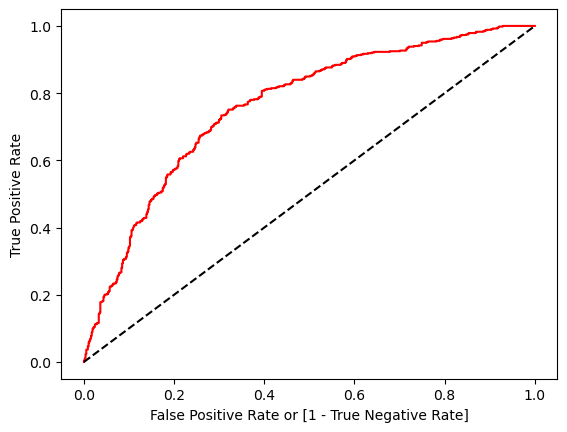

In [15]:
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score

fpr , tpr, thresholds = roc_curve(y, classifier.predict_proba(x)[:,1])
auc = roc_auc_score(y, y_pred)

import matplotlib.pyplot as plt
plt.plot(fpr,tpr,color='red',label='logit model (area = %0.2f)' % auc)
plt.plot([0,1],[0,1],'k--')
plt.xlabel('False Positive Rate or [1 - True Negative Rate]')
plt.ylabel('True Positive Rate')

In [16]:
auc

np.float64(0.7108589063606365)

In [17]:
classifier.predict_proba(x)

array([[9.99996954e-01, 3.04592568e-06],
       [4.92832148e-01, 5.07167852e-01],
       [4.24835532e-01, 5.75164468e-01],
       ...,
       [2.60970584e-01, 7.39029416e-01],
       [7.14046063e-01, 2.85953937e-01],
       [3.19569059e-01, 6.80430941e-01]])

In [18]:
from pickle import dump 

In [19]:
dump(classifier, open('clsf.pkl', 'wb'))